# Практична робота №10
## Автентифікація за клавіатурним почерком


Однакова довжина всіх вибірок, поріг P = 0,9 або 0,95, критерій Стьюдента з 2n−2 ступенями свободи. Бракована перевірка — відмова в автентифікації.

In [13]:
%pip install scipy matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### Алгоритм

Для фрази «Ходи куди хочеш» маємо 15 символів і **n = 14 інтервалів**. Пробіли враховуються, Enter та Shift — ні. Вимірюється час між натисканнями сусідніх символьних клавіш.

Пошук грубих помилок за методичкою: для кожного інтервалу обчислюються середнє та вибіркова дисперсія решти інтервалів, потім |yᵢ−Mᵢ|/Sᵢ порівнюється з t(0,975; m−2). Після видалення перевірка повторюється. Рівень значущості цього етапу — 0,05.

**Якщо після очищення залишилося не n інтервалів, спроба бракується.** Значення не доповнюються й не замінюються. Браковане навчальне введення не стає еталоном. Бракована перевірка зараховується як відмова й входить у знаменник показника помилки.

Порівняння виконується тільки при n₁ = n₂ = n:

- F = max(s₁², s₂²)/min(s₁², s₂²); критичне значення F(1−α; n−1, n−1) за алгоритмом методички.
- sₚ² = (s₁²+s₂²)/2; t = |M₁−M₂|/sqrt(sₚ²·2/n); критичне значення t(1−α/2; 2n−2).
- Позитивне порівняння потребує виконання обох умов: F ≤ Fкрит та t ≤ tкрит.
- P = r/kₑ, де r — число позитивних порівнянь, kₑ — фактичне число придатних еталонів. Допуск: P ≥ обраного порога. P — частка збігів, а не доведена ймовірність особи.

Навчання додатково показує взаємні збіги еталонів при α = 0,05. Це діагностика, яка не видаляє еталони й не змінює алгоритм допуску. Під час перевірок еталон фіксований.

In [ ]:
import json
import math
import time
import uuid
from pathlib import Path
import tkinter as tk
from tkinter import ttk, messagebox

from scipy.stats import t, f
import matplotlib.pyplot as plt

folder = Path("prac10")
folder.mkdir(exist_ok=True)
version = 3

In [15]:
def get_stats(values):
    if len(values) < 2:
        raise ValueError("Недостатньо інтервалів для дисперсії.")
    mean = sum(values) / len(values)
    var = sum((x - mean) ** 2 for x in values) / (len(values) - 1)
    return mean, var


def clean(values):
    values, removed = list(values), []
    while len(values) >= 3:
        limit = float(t.ppf(0.975, len(values) - 2))
        for i, value in enumerate(values):
            mean, var = get_stats(values[:i] + values[i + 1:])
            diff = abs(value - mean)
            score = diff / math.sqrt(var) if var > 0 else (math.inf if diff else 0.0)
            if score > limit:
                removed.append(values.pop(i))
                break
        else:
            break
    return values, removed


def make_sample(raw, phrase, typed):
    raw = list(raw)
    n = len(phrase) - 1
    reason = ""
    if typed != phrase:
        reason = "Контрольну фразу введено неправильно."
    elif len(raw) != n or any(not math.isfinite(v) or v <= 0 for v in raw):
        reason = "Некоректні виміри або кількість інтервалів."
    values, removed = clean(raw) if not reason else ([], [])
    if not reason and len(values) != n:
        reason = f"Після очищення залишилося {len(values)} інтервалів із {n}. Спробу забраковано."
    mean, var = get_stats(values) if len(values) >= 2 else (None, None)
    return {"raw": raw, "values": values, "removed": removed,
            "mean": mean, "var": var, "valid": not reason, "reason": reason}


def compare(x, y, alpha):
    if len(x) != len(y) or len(x) < 3:
        raise ValueError("Потрібні вибірки однакової довжини n ≥ 3.")
    if not 0 < alpha < 1:
        raise ValueError("Рівень значущості має бути між 0 та 1.")
    if any(not math.isfinite(v) or v <= 0 for v in list(x) + list(y)):
        raise ValueError("Інтервали мають бути додатними скінченними числами.")
    n = len(x)
    mx, vx = get_stats(x)
    my, vy = get_stats(y)
    large, small = max(vx, vy), min(vx, vy)
    fp = large / small if small > 0 else (math.inf if large else 1.0)
    ft = float(f.ppf(1 - alpha, n - 1, n - 1))
    pooled = (vx + vy) / 2
    se = math.sqrt(pooled * 2 / n)
    tp = abs(mx - my) / se if se > 0 else (math.inf if mx != my else 0.0)
    tt = float(t.ppf(1 - alpha / 2, 2 * n - 2))
    return fp, ft, tp, tt, bool(fp <= ft and tp <= tt)


def check(profile, sample, alpha, threshold):
    if threshold not in (0.9, 0.95):
        raise ValueError("Оберіть поріг 0,9 або 0,95.")
    refs = profile["samples"]
    n = len(profile["phrase"]) - 1
    if not refs:
        raise ValueError("Немає придатних еталонів. Виконайте навчання.")
    if any(not s["valid"] or len(s["values"]) != n for s in refs):
        raise ValueError("Еталони мають містити рівно n інтервалів. Виконайте нове навчання.")
    if not sample["valid"] or len(sample["values"]) != n:
        return [], None, False
    rows = [compare(s["values"], sample["values"], alpha) for s in refs]
    probability = sum(row[4] for row in rows) / len(rows)
    return rows, probability, probability >= threshold


def error_rates(records):
    own = [r for r in records if r["person"] == "Власник"]
    other = [r for r in records if r["person"] == "Інша людина"]
    return len(own), sum(not r["accepted"] for r in own), len(other), sum(r["accepted"] for r in other)


def consistency(samples, alpha=0.05):
    if len(samples) < 2:
        return []
    return [sum(compare(s["values"], other["values"], alpha)[4]
                for j, other in enumerate(samples) if i != j) / (len(samples) - 1)
            for i, s in enumerate(samples)]


def save_data(path, data):
    temp = path.with_suffix(".tmp")
    temp.write_text(json.dumps(data, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    temp.replace(path)

### Інтерфейс і облік спроб

У полі «Кількість введень у серії» я задаю, скільки разів потрібно ввести фразу й натиснути Enter. Тут враховуються всі спроби, навіть браковані. Наприклад, якщо обрати 10, серія завершиться після десятого надсилання. Якщо після навчання придатних зразків мало, можна провести нову, довшу серію.

Під час навчання програма записує всі спроби в журнал, але для формування еталона використовує лише придатні. Якщо жодного придатного зразка немає, пройти перевірку неможливо. Після завершення нового навчання попередній профіль замінюється новим, навіть якщо всі нові спроби були бракованими.

За допомогою чекбокса я вказую, хто проходить перевірку: власник профілю чи інша людина. На рішення програми цей вибір не впливає — він потрібен для правильного підрахунку помилок. Для власника рахується помилка першого роду — коли програма його не розпізнала. Для іншої людини — помилка другого роду, коли програма помилково прийняла її за власника.

Результати зберігаються окремо для кожної серії. У загальному підсумку також окремо враховуються результати для власника й іншої людини та для різних значень α і порога.


In [16]:
class App:
    def __init__(self, root):
        self.root = root
        self.active = False
        self.profile = None
        self.records = []
        self.held = set()
        self.times, self.typed, self.last = [], "", None
        root.title("Клавіатурний почерк — практична №10")
        root.geometry("980x820")
        frame = ttk.Frame(root, padding=12)
        frame.pack(fill="both", expand=True)
        self.mode = tk.StringVar(value="Навчання")
        self.count = tk.StringVar(value="10")
        self.alpha = tk.StringVar(value="0.05")
        self.threshold = tk.StringVar(value="0.9")
        self.owner = tk.BooleanVar(value=True)
        self.phrase = tk.StringVar(value="Ходи куди хочеш")
        self.controls = []
        fields = [("Режим", self.mode, ["Навчання", "Перевірка"]),
                  ("Кількість введень у серії", self.count, [3, 4, 5, 6, 7, 8, 9, 10, 20, 30]),
                  ("Рівень значущості α", self.alpha, [0.2, 0.1, 0.05, 0.02, 0.01, 0.005, 0.002, 0.001]),
                  ("Поріг P для допуску", self.threshold, ["0.9", "0.95"])]
        for label, var, values in fields:
            row = ttk.Frame(frame)
            row.pack(fill="x", pady=3)
            ttk.Label(row, text=label, width=30).pack(side="left")
            box = ttk.Combobox(row, textvariable=var, values=values, state="readonly", width=24)
            box.pack(side="left")
            self.controls.append(box)
        self.owner_box = ttk.Checkbutton(frame, text="Перевірку проходить власник еталону", variable=self.owner)
        self.owner_box.pack(anchor="w", pady=5)
        ttk.Label(frame, text="Контрольна фраза:").pack(anchor="w")
        self.phrase_box = ttk.Entry(frame, textvariable=self.phrase)
        self.phrase_box.pack(fill="x")
        buttons = ttk.Frame(frame)
        buttons.pack(pady=6)
        self.button = ttk.Button(buttons, text="Почати серію", command=self.start)
        self.button.pack(side="left", padx=4)
        self.stop_button = ttk.Button(buttons, text="Зупинити серію", command=self.stop, state="disabled")
        self.stop_button.pack(side="left", padx=4)
        self.status = tk.StringVar(value="Оберіть режим і почніть серію.")
        self.progress = tk.StringVar(value="")
        ttk.Label(frame, textvariable=self.status, wraplength=920).pack(anchor="w")
        ttk.Label(frame, textvariable=self.progress, wraplength=920).pack(anchor="w")
        ttk.Label(frame, text="Enter — надіслати. Esc / Backspace / Delete — скинути поточний набір.").pack(anchor="w", pady=4)
        self.entry = ttk.Entry(frame, font=("Arial", 16), state="disabled")
        self.entry.pack(fill="x", pady=5)
        self.entry.bind("<KeyPress>", self.key_down)
        self.entry.bind("<KeyRelease>", lambda e: self.held.discard(e.keycode))
        self.entry.bind("<FocusOut>", lambda e: self.reset_input() if self.active else None)
        self.entry.bind("<<Paste>>", lambda e: "break")
        self.entry.bind("<Button-2>", lambda e: "break")
        log = ttk.Frame(frame)
        log.pack(fill="both", expand=True)
        self.output = tk.Text(log, height=22, wrap="word", state="disabled")
        scroll = ttk.Scrollbar(log, command=self.output.yview)
        self.output.configure(yscrollcommand=scroll.set)
        scroll.pack(side="right", fill="y")
        self.output.pack(side="left", fill="both", expand=True)

    def show(self, text):
        self.output.configure(state="normal")
        self.output.delete("1.0", "end")
        self.output.insert("end", text)
        self.output.configure(state="disabled")

    def reset_input(self):
        self.times, self.typed, self.last = [], "", None
        self.held.clear()
        self.entry.delete(0, "end")

    def lock(self, active):
        self.active = active
        for box in self.controls:
            box.configure(state="disabled" if active else "readonly")
        self.owner_box.configure(state="disabled" if active else "normal")
        self.phrase_box.configure(state="disabled" if active else "normal")
        self.button.configure(state="disabled" if active else "normal")
        self.stop_button.configure(state="normal" if active else "disabled")
        self.entry.configure(state="normal")
        self.reset_input()
        if not active:
            self.entry.configure(state="disabled")

    def start(self):
        if self.active:
            return
        try:
            self.total = int(self.count.get())
            self.a = float(self.alpha.get().replace(",", "."))
            self.cutoff = float(self.threshold.get().replace(",", "."))
            if self.total not in (3, 4, 5, 6, 7, 8, 9, 10, 20, 30):
                raise ValueError("Оберіть кількість введень зі списку.")
            if not 0 < self.a < 1 or self.cutoff not in (0.9, 0.95):
                raise ValueError("Некоректний рівень значущості або поріг.")
            self.person = "Власник" if self.owner.get() else "Інша людина"
            if self.mode.get() == "Перевірка":
                path = folder / "etalon.json"
                if not path.exists():
                    raise ValueError("Спочатку виконайте навчання у цій версії програми.")
                profile = json.loads(path.read_text(encoding="utf-8"))
                if profile.get("version") != version:
                    raise ValueError("Профіль іншої версії. Виконайте нове навчання.")
                if not profile["samples"]:
                    raise ValueError("Профіль не містить придатних еталонів. Повторіть навчання.")
                n = len(profile["phrase"]) - 1
                if n < 3 or any(not s["valid"] or len(s["values"]) != n or
                               any(not math.isfinite(v) or v <= 0 for v in s["values"])
                               for s in profile["samples"]):
                    raise ValueError("Некоректний профіль: усі еталони повинні мати n інтервалів.")
                self.profile = profile
                self.phrase.set(profile["phrase"])
                path = folder / "checks.json"
                history = json.loads(path.read_text(encoding="utf-8")) if path.exists() else []
                self.records = [r for r in history if r["profile_id"] == profile["id"]]
            elif len(self.phrase.get()) < 4:
                raise ValueError("Фраза має містити щонайменше чотири символи.")
            self.samples, self.training, self.session = [], [], []
            self.done = self.rejected = 0
            self.series_id = uuid.uuid4().hex
            self.saved_training = False
            self.lock(True)
            n = len(self.phrase.get()) - 1
            self.show(f"Потрібно {n} інтервалів у кожній придатній спробі.\n"
                      f"Серія містить {self.total} надсилань через Enter, включно з бракованими.")
            self.progress.set(f"Введень: 0/{self.total}")
            self.status.set(f"Спроба 1/{self.total}. Фраза: {self.phrase.get()}")
            self.entry.focus_set()
        except (OSError, ValueError, KeyError, TypeError) as exc:
            messagebox.showerror("Початок роботи", str(exc), parent=self.root)

    def key_down(self, event):
        if not self.active:
            return "break"
        if event.keysym in ("Escape", "BackSpace", "Delete"):
            self.reset_input()
        elif event.keysym in ("Return", "KP_Enter"):
            if self.typed:
                self.finish_input()
        elif event.char and event.char.isprintable() and not event.state & 0xC:
            if event.keycode in self.held:
                return "break"
            self.held.add(event.keycode)
            now = time.perf_counter()
            if self.last is not None:
                self.times.append(now - self.last)
            self.last = now
            self.typed += event.char
            self.entry.insert("end", event.char)
        return "break"

    def stop(self):
        if not self.active:
            return
        self.lock(False)
        self.status.set("Серію зупинено. Незавершене навчання не збережено."
                        if self.mode.get() == "Навчання" else
                        "Серію зупинено. Завершені перевірки збережено.")

    def finish_input(self):
        try:
            sample = make_sample(self.times, self.phrase.get(), self.typed)
            n = len(self.phrase.get()) - 1
            text = f"Введення {self.done + 1}/{self.total}\n"
            text += "Сирі інтервали, с: " + ", ".join(f"{v:.5f}" for v in sample["raw"]) + "\n"
            text += f"Після очищення: {len(sample['values'])}/{n}; відкинуто: {len(sample['removed'])}.\n"
            if sample["removed"]:
                text += "Відкинуті інтервали, с: " + ", ".join(f"{v:.5f}" for v in sample["removed"]) + "\n"
            if sample["mean"] is not None:
                text += f"Середнє: {sample['mean']:.6f} с; дисперсія: {sample['var']:.8f} с².\n"
            if not sample["valid"]:
                text += "Брак: " + sample["reason"] + "\n"
            if self.mode.get() == "Навчання":
                sample["attempt"] = self.done + 1
                self.training.append(sample)
                if sample["valid"]:
                    self.samples.append(sample)
                else:
                    self.rejected += 1
                text += f"Еталонів: {len(self.samples)}; бракованих введень: {self.rejected}.\n"
                if self.done + 1 == self.total:
                    profile = {"version": version, "id": uuid.uuid4().hex, "phrase": self.phrase.get(),
                               "n": n, "samples": self.samples, "training": self.training,
                               "rejected_count": self.rejected}
                    save_data(folder / "etalon.json", profile)
                    self.saved_training = True
                    text += "Навчання збережено. Старі перевірки належать попередньому профілю.\n"
                    if self.samples:
                        k = len(self.samples)
                        text += f"Для порога {self.cutoff} потрібно {math.ceil(k * self.cutoff)} збігів із {k}.\n"
                        if k < 10:
                            text += "Еталонів менше 10: P змінюється великими кроками; можна провести довшу навчальну серію.\n"
                        scores = consistency(self.samples)
                        for ref, score in zip(self.samples, scores):
                            text += f"Навчальне введення №{ref['attempt']}: частка збігів з іншими еталонами {score:.3f}.\n"
                    else:
                        text += "Жодного придатного еталону. Перевірка недоступна: повторіть навчання.\n"
            else:
                rows, probability, accepted = check(self.profile, sample, self.a, self.cutoff)
                for ref, row in zip(self.profile["samples"], rows):
                    fp, ft, tp, tt, match = row
                    text += (f"Еталон з навчального введення №{ref['attempt']}: "
                             f"M={ref['mean']:.6f}, s²={ref['var']:.8f}; "
                             f"F={fp:.3f}/{ft:.3f}, t={tp:.3f}/{tt:.3f}; "
                             + ("збіг" if match else "немає збігу") + ".\n")
                record = {"profile_id": self.profile["id"], "series_id": self.series_id,
                          "attempt": self.done + 1, "person": self.person, "alpha": self.a,
                          "threshold": self.cutoff, "sample": sample, "p": probability, "accepted": accepted}
                save_data(folder / "checks.json", self.records + [record])
                self.records.append(record)
                self.session.append(record)
                self.rejected += not sample["valid"]
                if probability is not None:
                    text += f"P = {sum(row[4] for row in rows)}/{len(rows)} = {probability:.3f}.\n"
                else:
                    text += "P не обчислюється: введення браковане.\n"
                text += "Рішення: допущено.\n" if accepted else "Рішення: відмовлено.\n"
                n0, n1, m0, n2 = error_rates(self.session)
                if self.person == "Власник":
                    text += f"Помилка першого роду в цій серії: {n1}/{n0} = {n1 / n0:.1%}.\n"
                else:
                    text += f"Помилка другого роду в цій серії: {n2}/{m0} = {n2 / m0:.1%}.\n"
                correct = n0 - n1 + m0 - n2
                text += f"Правильних рішень у цій серії: {correct}/{len(self.session)} = {correct / len(self.session):.1%}."
            self.done += 1
            self.show(text)
            self.progress.set(f"Введень: {self.done}/{self.total}; бракованих: {self.rejected}"
                              + (f"; еталонів: {len(self.samples)}" if self.mode.get() == "Навчання" else ""))
            self.reset_input()
            if self.done == self.total:
                self.lock(False)
                if self.mode.get() == "Навчання":
                    self.status.set(f"Навчання завершено: {self.done} введень, {len(self.samples)} еталонів. "
                                    + ("Можна перейти до перевірки." if self.samples else
                                       "Немає еталонів. Повторіть навчання."))
                else:
                    self.status.set("Серію перевірок завершено. Усі рішення збережено.")
            else:
                self.status.set(f"Наступне введення: {self.done + 1}/{self.total}. Фраза: {self.phrase.get()}")
        except (OSError, ValueError, KeyError, TypeError) as exc:
            self.stop()
            messagebox.showerror("Обробка введення", str(exc), parent=self.root)

In [17]:
root = tk.Tk()
app = App(root)
root.mainloop()


### Аналіз результатів

Для власника: P₁ = кількість відмов / кількість його перевірок. Для іншої людини: P₂ = кількість допусків / кількість її перевірок. Я вказую, хто саме вводить фразу, але програма не використовує цю інформацію для розпізнавання. Тому в кожній серії рахується лише відповідний вид помилки.

Точність усієї вибірки — (допуски власника + відмови іншій людині) / усі перевірки. Окремо показуються результати кожної групи та кількість бракованих введень. Браковані перевірки також входять у розрахунок точності й помилок. Якщо перевірку проходив лише власник або лише інша людина, цього ще недостатньо для повної оцінки розпізнавання.

Велику кількість бракованих введень теж потрібно враховувати під час аналізу. За уточненням, якщо під час статистичного очищення було видалено хоча б один інтервал, таку спробу потрібно відхилити.

Якість розпізнавання я оцінюю за результатами перевірок. Метод порівнює середнє значення та дисперсію часових інтервалів, але не враховує їхню послідовність. Тому він може плутати людей зі схожими показниками набору. 

Фраза: Ходи куди хочеш | потрібно інтервалів: 14
Навчальних введень: 10
Придатних еталонів: 4
Бракованих навчальних введень: 6
Введення | залишилося | M, с | s², с² | еталон
1 | 13/14 | 0.219082 | 0.00386313 | Ні
  Причина: Після очищення залишилося 13 інтервалів із 14. Спробу забраковано.
2 | 13/14 | 0.199614 | 0.00522053 | Ні
  Причина: Після очищення залишилося 13 інтервалів із 14. Спробу забраковано.
3 | 13/14 | 0.214402 | 0.00531190 | Ні
  Причина: Після очищення залишилося 13 інтервалів із 14. Спробу забраковано.
4 | 14/14 | 0.200894 | 0.00371610 | Так
5 | 14/14 | 0.211045 | 0.00396135 | Так
6 | 14/14 | 0.210588 | 0.00229723 | Так
7 | 12/14 | 0.202831 | 0.00475473 | Ні
  Причина: Після очищення залишилося 12 інтервалів із 14. Спробу забраковано.
8 | 12/14 | 0.195383 | 0.00251999 | Ні
  Причина: Після очищення залишилося 12 інтервалів із 14. Спробу забраковано.
9 | 13/14 | 0.218770 | 0.00455759 | Ні
  Причина: Після очищення залишилося 13 інтервалів із 14. Спробу забраковано.
10 |

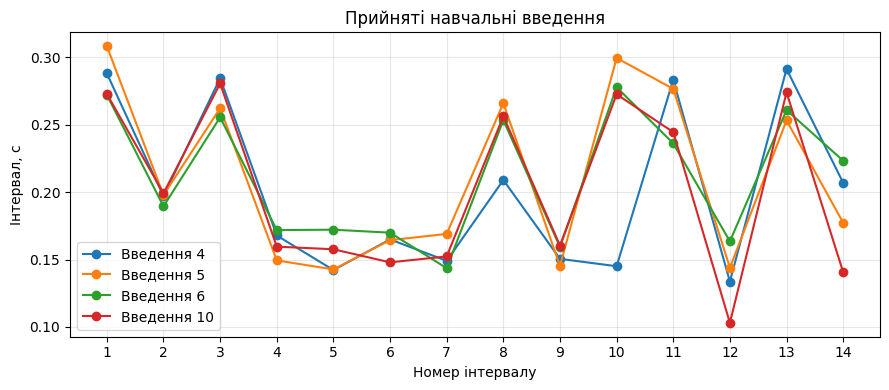


Серія 1: Власник; α=0.05; поріг=0.9
Введення | P | рішення | брак
1 | — | Відмовлено | Так
2 | 1.000 | Допущено | Ні
3 | — | Відмовлено | Так
4 | 1.000 | Допущено | Ні
5 | 1.000 | Допущено | Ні
6 | 1.000 | Допущено | Ні
7 | 1.000 | Допущено | Ні
8 | — | Відмовлено | Так
9 | — | Відмовлено | Так
10 | 1.000 | Допущено | Ні
Помилка першого роду: 4/10 = 40.0%
Бракованих введень: 4

Серія 2: Інша людина; α=0.05; поріг=0.9
Введення | P | рішення | брак
1 | — | Відмовлено | Так
2 | — | Відмовлено | Так
3 | — | Відмовлено | Так
4 | — | Відмовлено | Так
5 | — | Відмовлено | Так
6 | — | Відмовлено | Так
7 | — | Відмовлено | Так
8 | 0.000 | Відмовлено | Ні
9 | — | Відмовлено | Так
10 | — | Відмовлено | Так
Помилка другого роду: 0/10 = 0.0%
Бракованих введень: 9

ПІДСУМОК ДЛЯ ПОТОЧНОГО ПРОФІЛЮ

α=0.05; поріг=0.9
Власник: помилка першого роду 4/10 = 40.0%; брак 4.
Інша людина: помилка другого роду 0/10 = 0.0%; брак 9.
Точність на виконаних перевірках: 16/20 = 80.0%


In [18]:
path = folder / "etalon.json"
if not path.exists():
    print("Спочатку виконайте навчання.")
else:
    profile = json.loads(path.read_text(encoding="utf-8"))
    print("Фраза:", profile["phrase"], "| потрібно інтервалів:", profile["n"])
    print("Навчальних введень:", len(profile["training"]))
    print("Придатних еталонів:", len(profile["samples"]))
    print("Бракованих навчальних введень:", profile["rejected_count"])
    print("Введення | залишилося | M, с | s², с² | еталон")
    for s in profile["training"]:
        mean = "—" if s["mean"] is None else f"{s['mean']:.6f}"
        var = "—" if s["var"] is None else f"{s['var']:.8f}"
        print(f"{s['attempt']} | {len(s['values'])}/{profile['n']} | {mean} | {var} | "
              + ("Так" if s["valid"] else "Ні"))
        if not s["valid"]:
            print("  Причина:", s["reason"])
    scores = consistency(profile["samples"])
    if scores:
        print("\nВзаємна узгодженість еталонів (α=0,05; без автоматичного видалення):")
        for s, score in zip(profile["samples"], scores):
            print(f"Навчальне введення №{s['attempt']}: {score:.3f}")
    if profile["samples"]:
        plt.figure(figsize=(9, 4))
        for s in profile["samples"]:
            plt.plot(range(1, profile["n"] + 1), s["values"], marker="o", label=f"Введення {s['attempt']}")
        plt.xlabel("Номер інтервалу")
        plt.ylabel("Інтервал, с")
        plt.title("Прийняті навчальні введення")
        plt.xticks(range(1, profile["n"] + 1))
        plt.grid(alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()
    else:
        print("Немає придатних еталонів. Потрібно нове навчання.")
    path = folder / "checks.json"
    records = json.loads(path.read_text(encoding="utf-8")) if path.exists() else []
    records = [r for r in records if r["profile_id"] == profile["id"]]
    if not records:
        print("\nПеревірок для цього профілю ще немає.")
    else:
        series = list(dict.fromkeys(r["series_id"] for r in records))
        for number, sid in enumerate(series, 1):
            group = [r for r in records if r["series_id"] == sid]
            first = group[0]
            print(f"\nСерія {number}: {first['person']}; α={first['alpha']}; поріг={first['threshold']}")
            print("Введення | P | рішення | брак")
            for r in group:
                prob = "—" if r["p"] is None else f"{r['p']:.3f}"
                print(f"{r['attempt']} | {prob} | " + ("Допущено" if r["accepted"] else "Відмовлено")
                      + " | " + ("Ні" if r["sample"]["valid"] else "Так"))
            n0, n1, m0, n2 = error_rates(group)
            if first["person"] == "Власник":
                print(f"Помилка першого роду: {n1}/{n0} = {n1 / n0:.1%}")
            else:
                print(f"Помилка другого роду: {n2}/{m0} = {n2 / m0:.1%}")
            print("Бракованих введень:", sum(not r["sample"]["valid"] for r in group))
        print("\nПІДСУМОК ДЛЯ ПОТОЧНОГО ПРОФІЛЮ")
        for alpha, threshold in sorted({(r["alpha"], r["threshold"]) for r in records}):
            group = [r for r in records if r["alpha"] == alpha and r["threshold"] == threshold]
            print(f"\nα={alpha}; поріг={threshold}")
            for person in ("Власник", "Інша людина"):
                subset = [r for r in group if r["person"] == person]
                if not subset:
                    print(person + ": немає перевірок.")
                    continue
                errors = sum((not r["accepted"]) if person == "Власник" else r["accepted"] for r in subset)
                kind = "першого" if person == "Власник" else "другого"
                bad = sum(not r["sample"]["valid"] for r in subset)
                print(f"{person}: помилка {kind} роду {errors}/{len(subset)} = {errors / len(subset):.1%}; брак {bad}.")
            n0, n1, m0, n2 = error_rates(group)
            correct = n0 - n1 + m0 - n2
            print(f"Точність на виконаних перевірках: {correct}/{len(group)} = {correct / len(group):.1%}")
            if not n0 or not m0:
                print("Для оцінювання обох груп потрібні окремі перевірки власника й іншої людини.")